In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import multivariate_normal
from mpl_toolkits.mplot3d import Axes3D
import random
from random import random
import pandas as pd
!pip install seaborn
import seaborn as sns
!pip install studenttmixture
from studenttmixture import EMStudentMixture

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [2]:
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.metrics import adjusted_rand_score
from scipy.spatial.distance import cdist
from sklearn.mixture import GaussianMixture

In [3]:
def generate_inliers(num_inliers, sed):
    np.random.seed(sed)

    #define GMM parameters
    mean_vectors=[[3,3],[0,0 ], [-3,-3]]

    covariances = [
                np.array([[1, 0], [0, 1]]),
                np.array([[2, 0], [0, 2]]),
                np.array([[1, 0], [0, 1]])
               ]
    weights = [1/3, 1/3, 1/3]
    gmm = GaussianMixture(n_components = 3, covariance_type = "full")
    gmm.means_ = np.array(mean_vectors)
    gmm.covariances_ = np.array(covariances)
    gmm.weights_ = np.array(weights)
    gmm.precisions_cholesky_ = np.linalg.cholesky(np.linalg.inv(gmm.covariances_))
    X, y = gmm.sample(num_inliers)
    return X, y

#generate a pool of outliers
def generate_outlier_pool(sed, max_outliers, low = -15, high = 15):
    np.random.seed(sed)
    return np.random.uniform(low = low, high = high, size = (max_outliers, 2))

#adding outliers sequentially
def add_outliers_sequential(X_base, y_base, outlier_pool, frac_target):
    n_inliers = np.sum(y_base!= -1)
    n_out_curr = np.sum(y_base == -1)
    #total outliers needed for this fraction
    n_out_needed = int(frac_target * n_inliers/(1-frac_target))
    #print(n_out_needed)
    n_new_out = n_out_needed- n_out_curr
    if n_new_out  <= 0:
        return X_base, y_base
        
    X_new_out = outlier_pool[n_out_curr: n_out_curr + n_new_out]
    y_new_out = np.array([-1] * n_new_out)

    X = np.vstack([X_base, X_new_out])
    y = np.hstack([y_base, y_new_out])
    perm = np.random.permutation(len(X))
    X = X[perm]
    y = y[perm]
    return X, y  

In [4]:
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


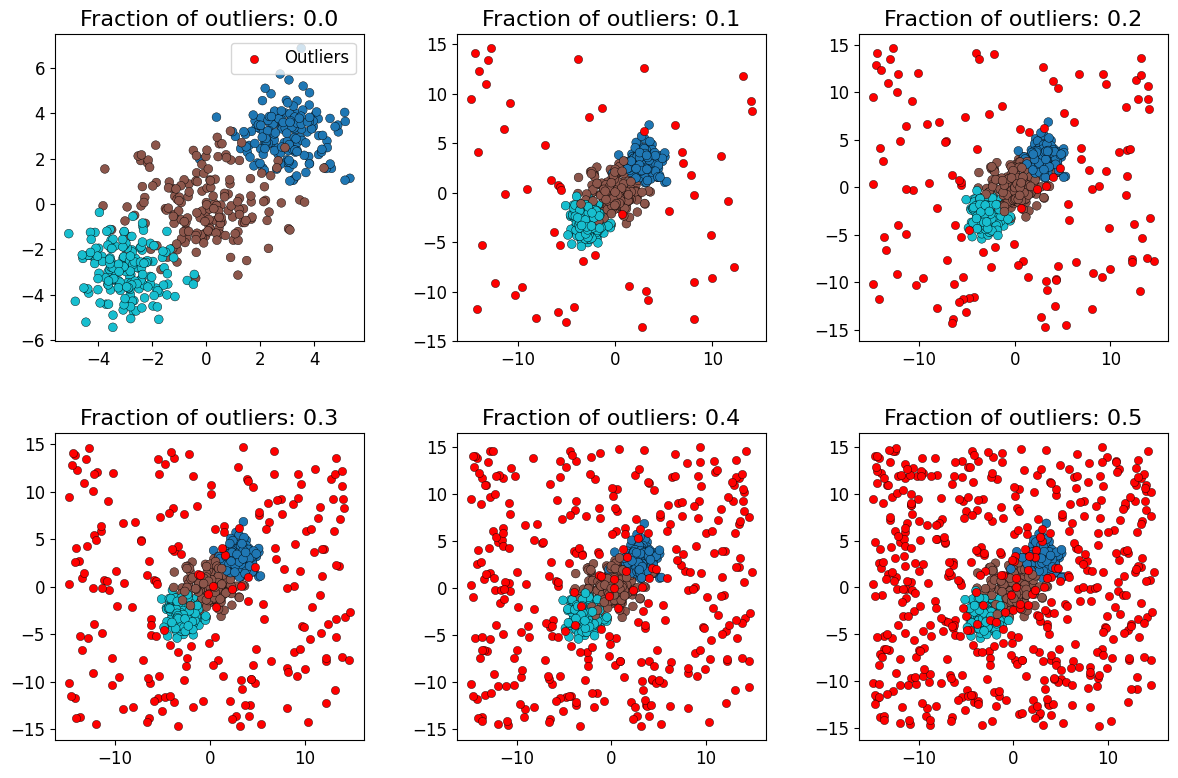

In [5]:
import matplotlib.pyplot as plt

# Parameters
num_inliers = 500
outlier_pool_size = 1000
fractions = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
seed = 42

# Generate inliers
X_inliers, y_inliers = generate_inliers(num_inliers=num_inliers, sed=seed)

# Generate outlier pool
outlier_pool = generate_outlier_pool(sed=seed, max_outliers=outlier_pool_size)

# Start with inliers only
X_base, y_base = X_inliers, y_inliers

# Plot sequentially
plt.figure(figsize=(12, 8))
for i, frac in enumerate(fractions):
    X1, y1 = add_outliers_sequential(X_base, y_base, outlier_pool, frac)

    plt.subplot(2, 3, i+1)
    # Plot inliers colored by true label
    plt.scatter(X1[y1!=-1,0], X1[y1!=-1,1], c=y1[y1!=-1], cmap='tab10', s=40, edgecolors  ="k", linewidths = 0.3)
    # Plot outliers
    plt.scatter(X1[y1==-1,0], X1[y1==-1,1], c='red', s=35, label='Outliers', edgecolors = "k", linewidths = 0.3)
    plt.title(f"Fraction of outliers: {frac:.1f}")
    #plt.xlabel('X1')
    #plt.ylabel('X2')
    if i == 0:
        plt.legend(loc='upper right')

    # Update base for next fraction
    X_base, y_base = X1, y1

plt.tight_layout()
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.savefig("outlier_plots_NSU.pdf", bbox_inches='tight')  # PDF for crisp text in Overleaf

plt.show()


In [6]:
num_inliers = 500
X_inliers, y_inliers = generate_inliers(num_inliers, sed= 20)

# Pre-generate a pool large enough for the largest fraction
max_outliers = 2000
outlier_pool = generate_outlier_pool(sed=42, max_outliers = max_outliers)

X_all, y_all = X_inliers, y_inliers
fractions = [0, 0.1, 0.2, 0.3, 0.4, 0.5]

for frac in fractions:
    X_all, y_all = add_outliers_sequential(X_all, y_all, outlier_pool, frac)
    n_out = np.sum(y_all == -1)
    n_total = len(y_all)
    print(f"Target fraction: {frac:.1f}, Total points: {n_total}, Outliers: {n_out}, Actual fraction: {n_out/n_total:.3f}")

Target fraction: 0.0, Total points: 500, Outliers: 0, Actual fraction: 0.000
Target fraction: 0.1, Total points: 555, Outliers: 55, Actual fraction: 0.099
Target fraction: 0.2, Total points: 625, Outliers: 125, Actual fraction: 0.200
Target fraction: 0.3, Total points: 714, Outliers: 214, Actual fraction: 0.300
Target fraction: 0.4, Total points: 833, Outliers: 333, Actual fraction: 0.400
Target fraction: 0.5, Total points: 1000, Outliers: 500, Actual fraction: 0.500


In [7]:
#PAM

In [8]:
!pip install scikit-learn-extra

from sklearn_extra.cluster import KMedoids

def pam(X_dat, y_dat, k, max_iter= 100):
    kmedoids = KMedoids(n_clusters = k, metric = "manhattan", method = "pam",init="random", max_iter = 100)
    kmedoids.fit(X_dat)
    labels = kmedoids.labels_
    non_outlier_indices = np.where(y_dat != -1)[0]
    #est_clust_wo_outliers = labels[non_outlier_indices]
    ari = metrics.adjusted_rand_score(labels[non_outlier_indices], y_dat[non_outlier_indices])#return labels, medoids
    return ari

Defaulting to user installation because normal site-packages is not writeable


In [9]:
#MM

In [10]:
#euclidean distance
def euclid_distance(p1, p2):
    return np.sqrt(np.sum((p1-p2)**2))

#functions for cluster assignment and cluster mean update
def assign_clusters(X_dat, clusters):
    n = X_dat.shape[0]
    for k in clusters:
        clusters[k]["points"] = []  # Clear points each iteration (moved here)

    for i in range(n):
        curr_X = X_dat[i, :]
        dist = [euclid_distance(curr_X, clusters[k]["center"]) for k in clusters]
        curr_cluster = np.argmin(dist)
        clusters[curr_cluster]["points"].append(i)  # Store index instead of point
    return clusters

def update_clusters(X_dat, clusters):
    for k in clusters:
        indices = clusters[k]["points"]
        if indices:  # Check non-empty
            cluster_members = X_dat[indices]  # Get points by index
            updated_center = cluster_members.mean(axis=0)
            clusters[k]["center"] = updated_center
    return clusters

In [11]:
#k-means style initializations for mean and covariance

def initialization_heur(X_dat, sed):
    
    np.random.seed(sed)
    n = X_dat.shape[0]

    indices = np.random.choice(n, 3, replace=False)
    centroids = X_dat[indices, :]
    c1 =  X_dat[indices, :]

    clusters = {0: {"center":c1[0,:], "points":[]},
                1: {"center":c1[1,:], "points":[]},
                2: {"center":c1[2,:], "points":[]}
                }

    clusters = assign_clusters(X_dat,clusters)
    clusters = update_clusters(X_dat,clusters)
    cov_initial1 = np.zeros((2, 2))

    for i in clusters[0]["points"]:
        diff =  (X_dat[i] - clusters[0]["center"]).reshape((2, 1))
        cov_initial1+= (diff @ diff.T)/ len(clusters[0]["points"])

    cov_initial2 = np.zeros((2, 2))
    for i in clusters[1]["points"]:
        diff =  (X_dat[i] - clusters[1]["center"]).reshape((2, 1))
        cov_initial2+= (diff @ diff.T)/ len(clusters[1]["points"])

    cov_initial3 = np.zeros((2, 2))
    for i in clusters[2]["points"]:
        diff =  (X_dat[i] - clusters[2]["center"]).reshape((2, 1))
        cov_initial3+= (diff @ diff.T)/ len(clusters[2]["points"])
    covar = [cov_initial1, cov_initial2, cov_initial3]
    return centroids, covar

In [12]:
def MM(X_dat, y_dat, sed, K=3, max_inner_iter=100, tol=1e-4):

    n, d = X_dat.shape

    # ensure float64
    X_dat = X_dat.astype(np.float64)

    # Initialization
    centroids, cov = initialization_heur(X_dat, sed)
    centroids = centroids.astype(np.float64)
    Omega = [np.linalg.inv(c.astype(np.float64)+1e-6*np.eye(d)) for c in cov]

    prev_centroids = centroids.copy()
    est_clust_assignments = np.zeros(n, dtype=int)

    for m in range(max_inner_iter):

            #  Assignment
            for i in range(n):
                dist = []

                for j in range(K):
                    const_term = ((1 / 2) ** d) * (1 / np.pi ** (d / 2)) \
                                 * (np.linalg.det(Omega[j]) ** 0.5) * (1 / n)

                    exp_term = (2 ** (1 - d / 2)) * (np.linalg.det(Omega[j]) ** 0.5) \
                               / (n * (np.pi ** (d / 2)))

                    diff = (X_dat[i] - centroids[j]).reshape((d, 1))
                    dist_val = const_term - exp_term * np.exp(
                        -0.5 * (diff.T @ Omega[j] @ diff)
                    )
                    dist.append(dist_val)

                est_clust_assignments[i] = np.argmin(dist)

            # centroid and covariance update for each cluster
            for c in range(K):
                indices = np.where(est_clust_assignments == c)[0]
                if len(indices) == 0:
                    continue

                # differences
                diffs = [(X_dat[e] - centroids[c]).reshape((d, 1)) for e in indices]

                # log-domain exponents
                log_exponents = np.array([-0.5 * (diff.T @ Omega[c] @ diff).item() for diff in diffs], dtype=np.float64)

                # log-sum-exp trick for safe sum of weights
                max_log = np.max(log_exponents)
                sum_weights = np.sum(np.exp(log_exponents - max_log)) * np.exp(max_log)

                # compute exact original weights safely
                weights = np.exp(log_exponents)

                # Centroid update
                weighted_sum = np.zeros(d, dtype=np.float64)
                for w, diff, e in zip(weights, diffs, indices):
                    weighted_sum += w * Omega[c].dot(X_dat[e])
                centroids[c] = np.linalg.inv(Omega[c]) @ (weighted_sum / sum_weights)
                
                
                # differences
                diffs = [(X_dat[e] - centroids[c]).reshape((d, 1)) for e in indices]

                # log-domain exponents
                log_exponents = np.array([-0.5 * (diff.T @ Omega[c] @ diff).item() for diff in diffs], dtype=np.float64)

                # log-sum-exp trick for safe sum of weights
                max_log = np.max(log_exponents)
                sum_weights = np.sum(np.exp(log_exponents - max_log)) * np.exp(max_log)

                # compute exact original weights safely
                weights = np.exp(log_exponents)
                # Covariance update
                weighted_cov = np.zeros((d, d), dtype=np.float64)
                for w, diff in zip(weights, diffs):
                    weighted_cov += w * (diff @ diff.T)
                weighted_cov /= sum_weights
                weighted_cov += 1e-6 * np.eye(d)  # small amount of regularization

                # Omega update
                Omega[c] = (np.trace(Omega[c] @ weighted_cov) / d) * np.linalg.inv(weighted_cov)

            # Check convergence
            diff_centroids = np.linalg.norm(prev_centroids - centroids, axis=1)
            if np.all(diff_centroids < tol):
                break
            prev_centroids = centroids.copy()
     
    #  Evaluation
    non_outlier_indices = np.where(y_dat != -1)[0]
    #est_clust_wo_outliers = est_clust_assignments[non_outlier_indices]
    ari = metrics.adjusted_rand_score(est_clust_assignments[non_outlier_indices ], y_dat[non_outlier_indices ])
    return ari, centroids, np.linalg.inv(Omega)

In [13]:
#trimmed K-means

In [14]:
import numpy as np
from itertools import permutations
from sklearn.metrics import adjusted_rand_score

def trimmed_kmeans(data, k, num_outliers, sed, max_iter=100, n_init=1, tol=1e-4):
    n = len(data)

    if num_outliers >= n:
        raise ValueError("num_outliers must be smaller than n")

    if k >= n - num_outliers:
        raise ValueError("k must be smaller than the number of inliers")

    #rng = np.random.default_rng(random_state)

    n_inliers = n - num_outliers

    best_cost = np.inf
    best_inliers = None
    best_labels = None
    best_centers = None

    for init in range(n_init):

        # Random initialization
        np.random.seed(sed)
        indices = np.random.choice(n, 3, replace=False)
        centers = data[indices, :]
        #center_indices = rng.choice(n, size=k, replace=False)
        #centers = data[center_indices].copy()

        previous_inliers = None

        for iteration in range(max_iter):
            # Assign every point to its nearest center
            distances = np.sum((data[:, None, :] - centers[None, :, :]) ** 2,axis=2)
            labels_all = np.argmin(distances, axis=1)

            # Distance to assigned center
            min_distances = distances[np.arange(n),labels_all]
            
            # Trim the furthest observations
            inliers = np.argpartition(min_distances,n_inliers - 1)[:n_inliers]
            inliers = np.sort(inliers)
            # Check whether trimming has converged
            if (previous_inliers is not None and np.array_equal(inliers, previous_inliers)):
                break

            previous_inliers = inliers.copy()
            # Recalculate cluster centers using inliers only
            new_centers = np.zeros_like(centers)
            for cluster in range(k):
                cluster_indices = inliers[labels_all[inliers] == cluster]
                if len(cluster_indices) == 0:
                    # Reinitialize an empty cluster
                    new_centers[cluster] = data[np.random.choice(inliers)]
                else:
                    new_centers[cluster] = np.mean(data[cluster_indices],axis=0)
            # Check center convergence
            center_shift = np.linalg.norm(new_centers - centers)
            centers = new_centers
            if center_shift < tol:
                break

        # Calculate final assignments
        distances = np.sum((data[:, None, :] - centers[None, :, :]) ** 2,axis=2)
        labels_all = np.argmin(distances, axis=1)
        min_distances = distances[np.arange(n),labels_all]
    
        # Trim again using final centers
        inliers = np.argpartition(min_distances,n_inliers - 1)[:n_inliers]
        inliers = np.sort(inliers)

        # Trimmed K-means objective
        cost = np.sum(min_distances[inliers])
        # Keep the best initialization
        if cost < best_cost:
            best_cost = cost
            best_inliers = inliers.copy()
            best_labels = labels_all[inliers].copy()
            best_centers = centers.copy()

    # Everything not retained is an outlier
    outliers = np.setdiff1d(np.arange(n),best_inliers)
    return best_inliers, best_labels, outliers, best_centers

In [15]:
def trimmed_kmeans_ari(data,k,num_outliers,true_labels,sed, max_iter=100,n_init=1,tol=1e-4,random_state=None):
    # Run trimmed K-means
    inliers, labels, outliers, centers = trimmed_kmeans(data=data, k=k, num_outliers=num_outliers,sed = sed,
        max_iter=max_iter, n_init=n_init, tol=tol)

    # Put the labels back into the original data ordering
    n = len(data)
    full_labels = np.full(n, -1)
    full_labels[inliers] = labels
    # 
    valid = (true_labels != -1) & (full_labels != -1)

    y_true_valid = true_labels[valid].astype(int)
    y_pred_valid = full_labels[valid].astype(int)

    best_score = -np.inf
    best_perm = None

    for perm in permutations(range(k)):
        perm = np.array(perm)
        score = np.mean(perm[y_true_valid] == y_pred_valid)
        if score > best_score:
            best_score = score
            best_perm = perm

    aligned_true = true_labels.astype(int).copy()
    mask = aligned_true != -1
    aligned_true[mask] = best_perm[aligned_true[mask]]
    rng = np.random.default_rng(0)
    final_pred = full_labels.copy()
    # Assign trimmed true-inliers randomly
    trimmed = ((final_pred == -1)& (aligned_true != -1))
    for i in np.where(trimmed)[0]:
        true_k = aligned_true[i]
        choices = np.delete(np.arange(k),true_k)
        final_pred[i] = rng.choice(choices)

    #ARI
    valid_ind = aligned_true != -1
    ari = adjusted_rand_score(aligned_true[valid_ind],final_pred[valid_ind])
    return ari

In [16]:
#Run all methods
num_datasets = 30
frac_outliers = np.arange(0.0, 0.6, 0.1)  # 0.0 to 0.5
ARI_PAM = np.zeros((len(frac_outliers), num_datasets))
ARI_TKMEANS = np.zeros((len(frac_outliers), num_datasets))
ARI_MM = np.zeros((len(frac_outliers), num_datasets))
ARI_TMIX = np.zeros((len(frac_outliers), num_datasets))

num_inliers = 500
max_outliers_pool = 2000  

for dat_ind in range(num_datasets):
    print(f"Dataset {dat_ind}")

    # Step 1: generate fixed inliers
    X_inliers, y_inliers = generate_inliers(num_inliers=num_inliers, sed=dat_ind)

    # Step 2: generate outlier pool
    outlier_pool = generate_outlier_pool(sed=dat_ind, max_outliers=max_outliers_pool)

    # Start with only inliers
    X_base, y_base = X_inliers, y_inliers

    for fr_ind, frac in enumerate(frac_outliers):
        # Step 3: add new outliers sequentially
        X1, y1 = add_outliers_sequential(X_base, y_base, outlier_pool, frac)

        #run trimmed k-means multiple times, and get best ARI and corresponding trimmed set for eval
        max_ari = -1
        for it in range(20):
            ari_curr= trimmed_kmeans_ari(X1, 3, np.sum(y1==-1), y1,it+dat_ind+fr_ind)
            if ari_curr > max_ari:
                max_ari = ari_curr
        ARI_TKMEANS[fr_ind, dat_ind] = max_ari
                
        # Run PAM multiple times and take the best ARI
        max_ari = -1
        for it in range(20):
            ari_curr= pam(X_dat=X1, y_dat=y1, k=3)
            if ari_curr > max_ari:
                max_ari = ari_curr
        ARI_PAM[fr_ind, dat_ind] = max_ari

        # run MM 
        max_ari = -1
        best_m = 0
        best_cov = 0
        for it in range(20):
            ari_curr, m, cov = MM(X1, y1, it+dat_ind+fr_ind)
            if ari_curr > max_ari:
                max_ari = ari_curr
                best_m = m
                best_cov = cov
        ARI_MM[fr_ind, dat_ind] = max_ari
    
        # Update base to include new outliers for next fraction

        #run mixture of t dist
        max_ari = -1
        for it in range(20):
            try:
               model = EMStudentMixture(n_components=3, max_iter=100, tol=1e-4, verbose=False)
               model.fit(X1)
        
        # check if model converged
               if model.df_ is None:
                  ari_curr = -1
               else:
                  labs = model.predict(X1)
                  ari_curr = metrics.adjusted_rand_score(labs[y1!=-1], y1[y1!=-1])
            
            except Exception as e:
               print(f"Iteration {it}: EM failed -> {e}")
               ari_curr = -1

            if ari_curr > max_ari:
               max_ari = ari_curr

        ARI_TMIX[fr_ind, dat_ind] = max_ari

        X_base, y_base = X1, y1
        
    print(np.mean(ARI_TKMEANS[:, 0:dat_ind+1], axis = 1))
    print(np.mean(ARI_PAM[:, 0:dat_ind+1], axis = 1))
    print(np.mean(ARI_MM[:, 0:dat_ind+1], axis = 1))
    print(np.mean(ARI_TMIX[:, 0:dat_ind+1], axis = 1))

Dataset 0
[0.80643998 0.77984188 0.76568451 0.75126986 0.70482909 0.66967973]
[0.80626255 0.81571335 0.82123397 0.80609463 0.42967827 0.42967827]
[0.79646314 0.81578225 0.79729703 0.50747396 0.518113   0.53038656]
[ 8.51612214e-01  5.38620811e-01  5.35149556e-01  5.35238111e-01
  5.30731912e-01 -2.08193195e-04]
Dataset 1
[0.84888647 0.81948804 0.81199577 0.78620236 0.74255387 0.70610233]
[0.82240408 0.84012234 0.83755364 0.82986412 0.44639039 0.44601998]
[0.80849729 0.84814719 0.83332254 0.62101373 0.65877586 0.53461332]
[ 8.74133945e-01  5.30042669e-01  5.33363682e-01  5.31064774e-01
  5.21291267e-01 -4.67479173e-05]
Dataset 2
[0.85205865 0.82322283 0.807818   0.78716695 0.74468901 0.70296244]
[0.82905067 0.84087672 0.84456831 0.84113142 0.58011044 0.45137806]
[0.8049536  0.85008538 0.84507599 0.70032445 0.72176504 0.60983812]
[8.67434822e-01 5.39830935e-01 5.03561956e-01 5.08247136e-01
 4.95455145e-01 6.59110402e-04]
Dataset 3
[0.84720952 0.81678469 0.80225941 0.77449992 0.73941326 0

In [17]:
np.save("ari_pam_NSU14OCT.npy", ARI_PAM)
np.save("ari_tmix_NSU14OCTdifwt.npy", ARI_TMIX)
np.save("ari_mm_NSU14OCTdifwt.npy", ARI_MM)
np.save("ari_tkmeans_NSU14OCTdifwt.npy", ARI_TKMEANS)